# Gabarito — Branqueamento e filtragem passa-banda

**Material complementar:** `intro-6-whiten-bandpass.ipynb`  
**Evento:** GW150914 · **Detetores:** L1 (Livingston) e H1 (Hanford)

Este gabarito resolve as três **questões de verificação** e apresenta a solução da seção **Pratique com Python**. As duas imagens de referência abaixo foram preservadas do notebook fornecido, que utiliza dados do detector **L1**. Na atividade prática, repetiremos a mesma análise com o detector **H1**.

> **Pré-requisito computacional:** para executar as células de aquisição e processamento de dados é necessário ter a biblioteca `gwpy` instalada e acesso à internet. A figura ilustrativa de 500 Hz utiliza apenas NumPy e Matplotlib.

## Questões de verificação

### 1. Em quais frequências o ruído é maior e o detector é mais sensível?

No espectro de densidade espectral de amplitude (ASD) dos dados brutos do L1, o ruído apresenta um **pico pronunciado próximo de 6 Hz**. Trata-se de uma região de ruído intenso, na qual a visualização de sinais gravitacionais é dificultada.

A ASD atinge seus menores valores em uma **faixa ampla, aproximadamente de 100 a 300 Hz**, desconsiderando as linhas espectrais estreitas. Nessa faixa, a sensibilidade do detector é relativamente maior: um ruído de menor amplitude permite identificar sinais mais fracos.

Não é adequado indicar uma frequência absolutamente única para a maior sensibilidade apenas por inspeção visual: a curva possui flutuações e linhas instrumentais, e a localização exata do mínimo depende do modo de estimar a ASD.

**ASD original do detector L1:**

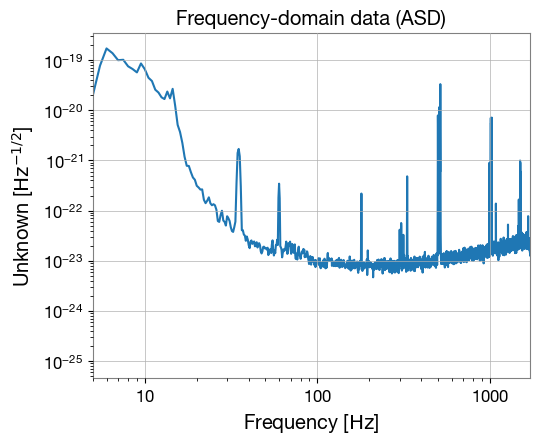

*Gráfico preservado do notebook de origem; os rótulos da figura ainda estão em inglês.*

### 2. Por que utilizar um filtro passa-banda de 40 a 400 Hz?

A faixa de **40–400 Hz** foi escolhida para destacar uma parte importante da evolução em frequência do sinal do **GW150914**, ao mesmo tempo que atenua:

- frequências **abaixo de 40 Hz**, nas quais os dados brutos apresentam excesso de ruído de baixa frequência;
- frequências **acima de 400 Hz**, que não são o foco dessa visualização e podem acrescentar ruído ao gráfico.

O filtro **não elimina todo o ruído** dentro da faixa escolhida e também **atenua partes do próprio sinal** fora dela. Esses limites são apropriados para o exemplo didático do notebook; não devem ser interpretados como uma faixa universal para todas as buscas de ondas gravitacionais.

O processamento utilizado é:

```python
white_data = strain.whiten()
bp_data = white_data.bandpass(40, 400)
```

Primeiro realiza-se o branqueamento, e depois aplica-se o filtro passa-banda.

### 3. Oscilações com 10 ciclos em 0,02 s

A frequência corresponde à quantidade de ciclos completos por unidade de tempo:

$$
f = \frac{N_\mathrm{ciclos}}{\Delta t}
  = \frac{10}{0{,}02\,\mathrm{s}}
  = \boxed{500\,\mathrm{Hz}}.
$$

Portanto, o período de uma oscilação é $T=1/f=0{,}002\,\mathrm{s}=2\,\mathrm{ms}$.

No gráfico temporal dos dados **brutos** do L1, as pequenas oscilações rápidas estão sobrepostas a oscilações lentas e maiores:

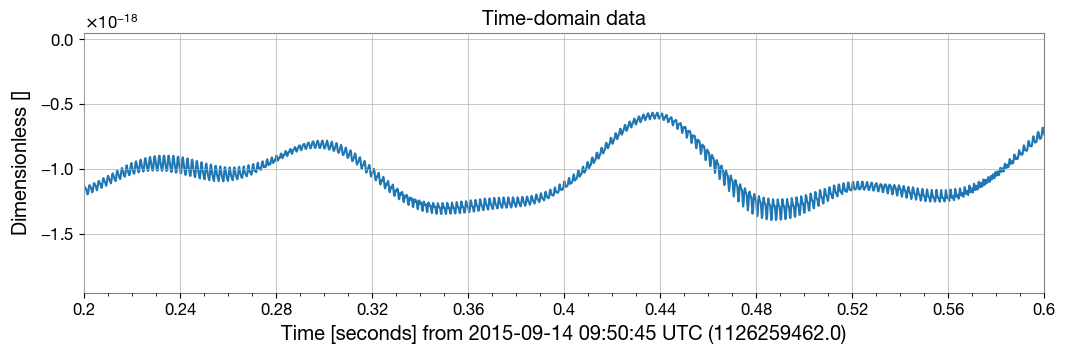

A ASD mostra uma **linha espectral estreita próxima de 500 Hz**, compatível com essa oscilação. Essa é uma característica instrumental/ruído dos dados, e não a identificação da frequência de fusão do GW150914.

*Gráfico preservado do notebook de origem; os rótulos da figura ainda estão em inglês.*

#### Verificação com uma senoide ilustrativa

A próxima célula gera uma senoide ideal de 500 Hz por 0,02 s, mostrando **10 ciclos completos**. É apenas uma demonstração matemática — **não são dados do LIGO**.

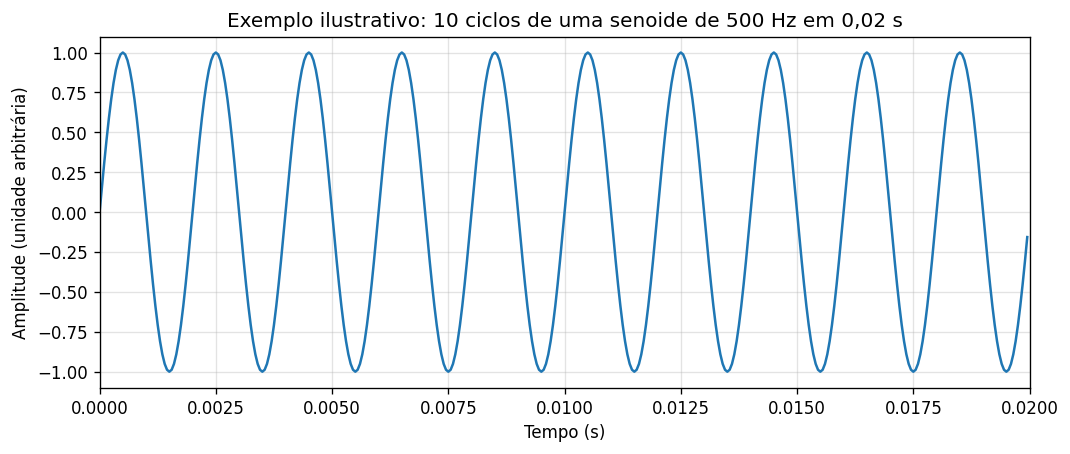

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Frequência e duração do exemplo ilustrativo
f = 500.0      # Hz
duracao = 0.02 # s
fs_demo = 20000.0  # amostras por segundo, apenas para desenhar a curva

tempo = np.arange(0, duracao, 1/fs_demo)
senoide = np.sin(2*np.pi*f*tempo)

plt.figure(figsize=(10, 3.8))
plt.plot(tempo, senoide)
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude (unidade arbitrária)')
plt.title('Exemplo ilustrativo: 10 ciclos de uma senoide de 500 Hz em 0,02 s')
plt.grid(alpha=0.35)
plt.xlim(0, duracao)
plt.show()

## Pratique com Python

### 1. Repetir a análise utilizando o detector H1 (Hanford)

As células a seguir repetem o procedimento do notebook original, alterando apenas o detector de `'L1'` para `'H1'`. Os parâmetros permanecem:

- instante de referência: $t_0=1126259462{,}4$ (GPS);
- dados baixados de $t_0-14$ até $t_0+14$ segundos;
- janela de visualização: $t_0\pm 0{,}2$ segundos;
- ASD calculada com `fftlength=2` segundos;
- filtro passa-banda de **40 a 400 Hz**.

**Importante:** executar essas células em ordem. Se `gwpy` não estiver instalado no kernel, execute `%pip install gwpy` em uma célula e reinicie o kernel.

In [ ]:
# -- Importar bibliotecas e baixar os dados do detector H1
import matplotlib.pyplot as plt
import numpy as np
from gwpy.timeseries import TimeSeries

t0 = 1126259462.4
dt = 0.2

# Os dados são obtidos do GWOSC, como no notebook original
strain_H1 = TimeSeries.fetch_open_data('H1', t0-14, t0+14, cache=False)

print('Detector:', strain_H1.channel or 'H1')
print('Frequência de amostragem:', strain_H1.sample_rate)
print('Duração:', strain_H1.duration)

#### a) Dados brutos no domínio do tempo e ASD

Este primeiro par de gráficos mostra como o ruído de baixa frequência domina o sinal bruto, antes de qualquer processamento.

In [ ]:
# -- Dados brutos: tempo e frequência
strain_H1.plot(xlim=(t0-dt, t0+dt),
               title='H1 — Dados brutos no domínio do tempo')

strain_H1.asd(fftlength=2).plot(
    xlim=(5, 1700),
    title='H1 — Dados brutos no domínio da frequência (ASD)')

#### b) Branqueamento dos dados

Aplicamos `.whiten()` para reduzir as diferenças de intensidade do ruído entre frequências, deixando sua ASD aproximadamente plana na faixa em que a estimativa é válida.

In [ ]:
# -- Branquear o sinal e apresentar os gráficos
white_H1 = strain_H1.whiten()

white_H1.plot(xlim=(t0-dt, t0+dt),
              title='H1 — Dados branqueados no domínio do tempo')

white_H1.asd(fftlength=2).plot(
    xlim=(5, 1700),
    title='H1 — Dados branqueados no domínio da frequência (ASD)')

#### c) Filtragem passa-banda de 40 a 400 Hz

Finalmente, aplicamos o mesmo filtro usado com L1. A aparência da forma de onda em H1 pode ser diferente da observada em L1, pois os detectores possuem ruídos e orientações diferentes.

In [ ]:
# -- Aplicar o filtro passa-banda aos dados branqueados
bp_H1 = white_H1.bandpass(40, 400)

bp_H1.plot(xlim=(t0-dt, t0+dt),
           title='H1 — Dados branqueados e filtrados no domínio do tempo')

bp_H1.asd(fftlength=2).plot(
    xlim=(5, 1700),
    title='H1 — Dados branqueados e filtrados no domínio da frequência (ASD)')

**Interpretação esperada:** o branqueamento reduz a predominância de componentes de ruído muito intensas; o passa-banda atenua frequências fora de 40–400 Hz. Com isso, a evolução rápida do sinal perto do GW150914 tende a ficar mais evidente na série temporal.

Os dois detectores **não precisam apresentar amplitudes, ruídos ou formas idênticas**. A comparação deve considerar as diferenças de resposta instrumental e o atraso entre as chegadas do sinal. A inspeção visual é uma atividade didática e não substitui os métodos estatísticos de detecção.

### 2. Explorar o aplicativo didático

O notebook original propõe explorar os efeitos do branqueamento e do filtro passa-banda no [aplicativo didático de processamento de sinais](https://share.streamlit.io/jkanner/streamlit-audio/main/app.py).

**Sugestão de verificação:** mantendo o mesmo sinal, ative e desative o branqueamento; depois altere os limites inferior e superior do filtro passa-banda. Observe se as componentes lentas e rápidas ficam mais ou menos evidentes e compare a forma do sinal e seu espectro.

O comportamento do aplicativo depende de sua disponibilidade e da configuração escolhida; o código acima permite reproduzir o procedimento diretamente com o GWpy.

---

### Síntese

- **ASD:** mostra a intensidade do ruído em função da frequência; menor ASD, em geral, significa maior sensibilidade instrumental.
- **Branqueamento:** redistribui o peso relativo das frequências, tornando a ASD do ruído aproximadamente plana.
- **Filtro passa-banda:** atenua componentes abaixo de 40 Hz e acima de 400 Hz, sem eliminar o ruído que permanece dentro da faixa.
- **500 Hz:** dez ciclos em 0,02 s; essa oscilação está associada a uma linha estreita visível na ASD.

**Fonte:** questões, parâmetros, figuras e procedimento baseados no notebook fornecido `intro-6-whiten-bandpass(1).ipynb`. Gabarito e comentários didáticos elaborados em português brasileiro.